In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

In [13]:
df = pd.read_csv("/content/Mall_Customers (1).csv")
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [14]:
df.shape

(200, 5)

In [15]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [17]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [18]:
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [19]:
# Select the numerical features used to group customers
X = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

# Display the selected features
print(X.head())

   Age  Annual Income (k$)  Spending Score (1-100)
0   19                  15                      39
1   21                  15                      81
2   20                  16                       6
3   23                  16                      77
4   31                  17                      40


In [20]:
# Create a scaler
scaler = StandardScaler()

# Standardize all selected features
X_scaled = scaler.fit_transform(X)

# Convert the scaled values back into a DataFrame
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

# Display the scaled data
print(X_scaled.head())

        Age  Annual Income (k$)  Spending Score (1-100)
0 -1.424569           -1.738999               -0.434801
1 -1.281035           -1.738999                1.195704
2 -1.352802           -1.700830               -1.715913
3 -1.137502           -1.700830                1.040418
4 -0.563369           -1.662660               -0.395980


elbow method:

In [23]:
wcss =[]
for k in range(1,11):
  Kmeans  = KMeans(n_clusters=k,random_state=42,n_init=10)
  Kmeans.fit(X_scaled)
  wcss.append(Kmeans.inertia_)
wcss

[599.9999999999999,
 389.38618895643714,
 295.21224615554877,
 205.22514747675913,
 168.2475801755683,
 133.86842085478855,
 117.01155455889815,
 103.87329152383714,
 93.0928911004172,
 82.38515364526597]

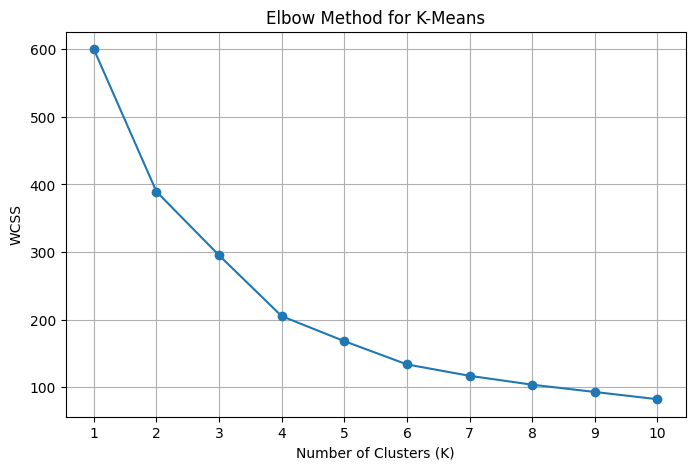

In [24]:
# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method for K-Means')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

k_mean clustering

In [25]:
# Choose the number of clusters based on the elbow graph
k = 4

# Create the K-Means model
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

# Assign a cluster label to every customer
kmeans_labels = kmeans.fit_predict(X_scaled)

# Store the labels in the original dataset
df['KMeans_Cluster'] = kmeans_labels

# Count the customers in each cluster
print(df['KMeans_Cluster'].value_counts().sort_index())

KMeans_Cluster
0    65
1    40
2    57
3    38
Name: count, dtype: int64


DBSCAN

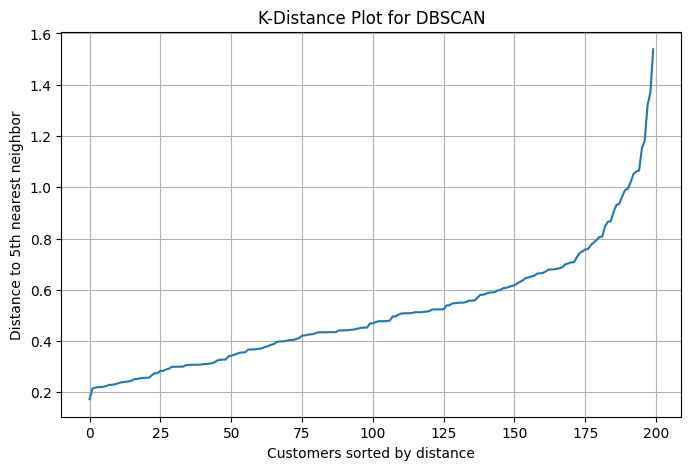

In [26]:
# Set the minimum number of neighbors to examine
min_samples = 5

# Find the distances to the nearest neighbors
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Get each customer's distance to the 5th nearest neighbor
k_distances = np.sort(distances[:, -1])

# Plot the sorted distances
plt.figure(figsize=(8, 5))
plt.plot(k_distances)

plt.xlabel('Customers sorted by distance')
plt.ylabel('Distance to 5th nearest neighbor')
plt.title('K-Distance Plot for DBSCAN')
plt.grid(True)
plt.show()

In [32]:
# Create the DBSCAN model
dbscan = DBSCAN(eps=0.6, min_samples=5)

# Assign a cluster label to each customer
dbscan_labels = dbscan.fit_predict(X_scaled)

# Store DBSCAN labels in the dataset
df['DBSCAN_Cluster'] = dbscan_labels

# Count customers in each DBSCAN group
print(df['DBSCAN_Cluster'].value_counts().sort_index())

DBSCAN_Cluster
-1     28
 0    137
 1     35
Name: count, dtype: int64


In [33]:
# Create a PCA model with two components
pca = PCA(n_components=2)

# Transform the scaled data into two dimensions
X_pca = pca.fit_transform(X_scaled)

# Display how much variance the two components explain
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.44266167 0.33308378]
Total variance explained: 0.7757454566976747


Visualize both clustering algorithms

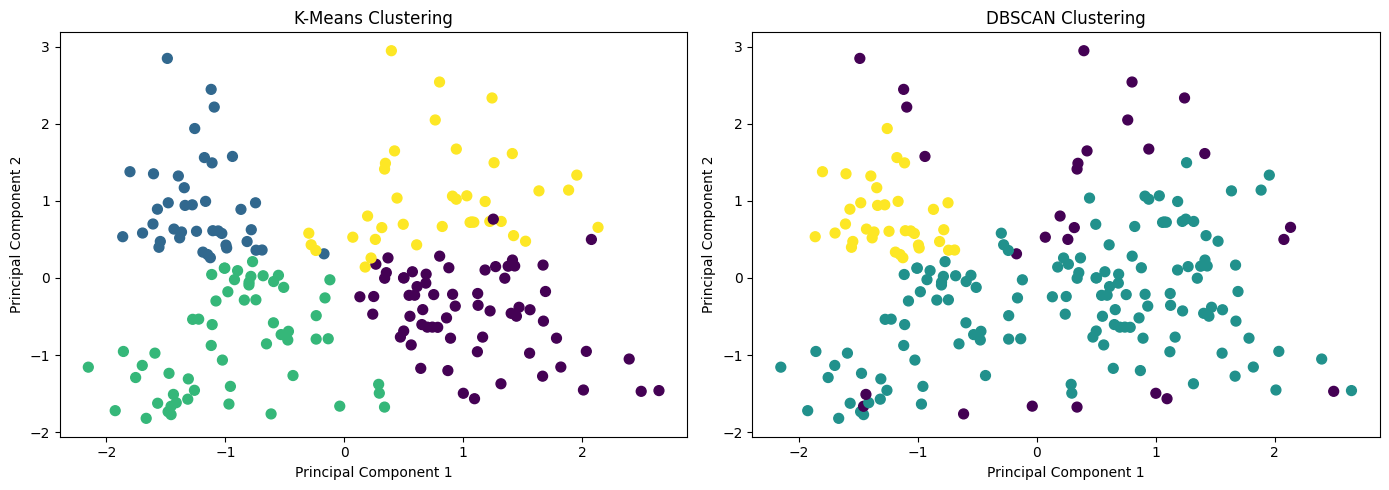

In [34]:
# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot K-Means clusters
axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    s=50
)

axes[0].set_title('K-Means Clustering')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')

# Plot DBSCAN clusters
axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_labels,
    cmap='viridis',
    s=50
)

axes[1].set_title('DBSCAN Clustering')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')

# Display both plots
plt.tight_layout()
plt.show()

Compare the results

In [36]:
# Count the clusters discovered by K-Means
kmeans_cluster_count = len(set(kmeans_labels))

# Count DBSCAN clusters, excluding noise label -1
dbscan_cluster_count = len(set(dbscan_labels) - {-1})

# Count the DBSCAN noise points
noise_count = np.sum(dbscan_labels == -1)

# Display the comparison
print("K-Means clusters:", kmeans_cluster_count)
print("DBSCAN clusters:", dbscan_cluster_count)
print("DBSCAN noise points:", noise_count)

print("\nK-Means customer counts:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

print("\nDBSCAN customer counts:")
print(pd.Series(dbscan_labels).value_counts().sort_index())

K-Means clusters: 4
DBSCAN clusters: 2
DBSCAN noise points: 28

K-Means customer counts:
0    65
1    40
2    57
3    38
Name: count, dtype: int64

DBSCAN customer counts:
-1     28
 0    137
 1     35
Name: count, dtype: int64
